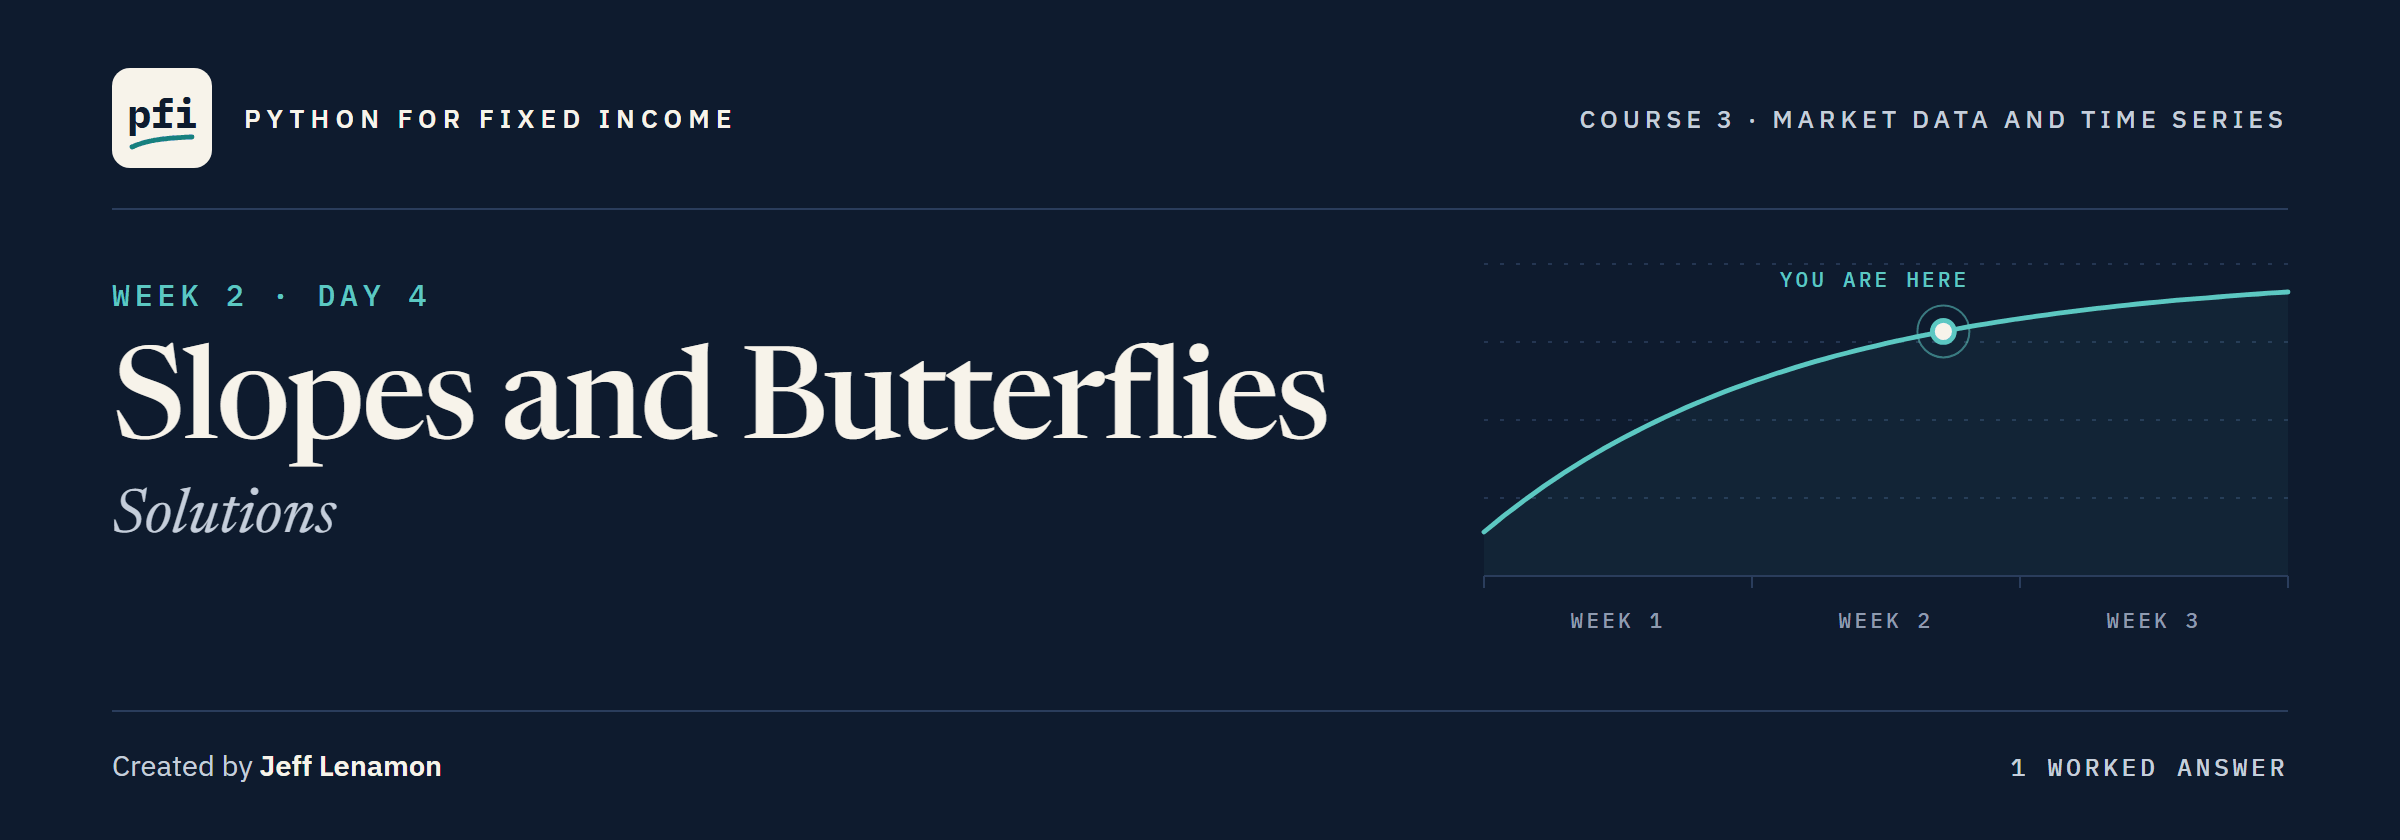

# Slopes and Butterflies: Solutions

Week 2, Day 4. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day4/09_slopes_and_butterflies_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module and tests as this notebook leaves them, the imports and the Treasury file, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 09 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(9, after=9)

Work folder pfi_course3_09_k4w7q2xr: 3 data files, Course 2's bondmath.py, marketdata.py as notebook 09 left it, 9 commits, tagged week1


In [2]:
import importlib
from datetime import date

import pandas as pd

import bondmath
import marketdata as md

treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
print(f'{len(treasury):,} market days, the last on {treasury.index[-1]:%Y-%m-%d}')

2,940 market days, the last on 2026-10-02


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [4]:
flies = md.butterfly_bp(treasury, '5 Yr', '10 Yr', '30 Yr')
ex1_fly = flies.loc['2026-10-02']
three_month_tens = md.slope_bp(treasury, '3 Mo', '10 Yr').loc['2026']
ex1_low = three_month_tens.min()
# the date as text, as an f-string writes it
ex1_low_date = f'{three_month_tens.idxmin():%Y-%m-%d}'
print(f'5s10s30s {ex1_fly:.2f} bp; lowest 3m10y of 2026 {ex1_low:.2f} bp on {ex1_low_date}')

5s10s30s -13.00 bp; lowest 3m10y of 2026 30.00 bp on 2026-02-27


In [5]:
check('Exercise 1 5s10s30s', ex1_fly, -12.9999999999999)
check('Exercise 1 the lowest 3m10y of 2026', ex1_low, 30.00000000000003)
check('Exercise 1 its date', ex1_low_date, '2026-02-27')

Exercise 1 5s10s30s: correct
Exercise 1 the lowest 3m10y of 2026: correct
Exercise 1 its date: correct


5s10s30s is -13 bp: the 10 Yr yields 6.5 bp less than the average of the 5 Yr and the 30 Yr.
On the other sign it is +13.
3m10y stayed above zero on every market day of 2026.

### Exercise 2

In [6]:
settlement = date(2026, 10, 2)
dv01s = {}
for tenor, years in [('5 Yr', 5), ('10 Yr', 10), ('30 Yr', 30)]:
    yield_pct = treasury.loc['2026-10-02', tenor]
    maturity = bondmath.add_months(settlement, 12 * years)
    dv01s[tenor] = bondmath.dv01(settlement, maturity, yield_pct, yield_pct)
ex2_w_short, w_belly, ex2_w_long = md.fly_weights(dv01s['5 Yr'], dv01s['10 Yr'], dv01s['30 Yr'])
print(f'faces per 1 of 10-year face: 5-year {ex2_w_short:.6f}, 30-year {ex2_w_long:.6f}')

faces per 1 of 10-year face: 5-year 0.880297, 30-year 0.267029


In [7]:
check('Exercise 2 the 5-year wing', ex2_w_short, 0.8802967938049596)
check('Exercise 2 the 30-year wing', ex2_w_long, 0.2670293403095496)

Exercise 2 the 5-year wing: correct
Exercise 2 the 30-year wing: correct


The 30-year's DV01 is the largest, so its wing needs the least face.
On 9.6's sheet with the 30-year in E, Excel's `=0.5*D4/C4` and `=0.5*D4/E4` return 0.880297 and 0.267029 from `MDURATION` and `PRICE`.

### Exercise 3

In [8]:
%%writefile -a marketdata.py


def curve_shape(curve_row: pd.Series) -> str:
    """Label one date's 2s10s slope as "positive", "zero", or "negative".

    Units: curve_row holds one date's yields in percent, with "2 Yr" and "10 Yr" among its labels.
    Convention: the slope is (10 Yr - 2 Yr) x 100 in bp, rounded to 6 decimals so the binary tail cannot
    move a zero; "positive" when the 10 Yr is higher. The label describes the shape on that date only.
    Raises ValueError if either yield is missing.
    """
    if curve_row[["2 Yr", "10 Yr"]].isna().any():
        raise ValueError("curve_row needs both the 2 Yr and the 10 Yr")
    # the same arithmetic as slope_bp, on one row
    slope = round((curve_row["10 Yr"] - curve_row["2 Yr"]) * 100, 6)
    if slope > 0:
        return "positive"
    if slope < 0:
        return "negative"
    return "zero"

Appending to marketdata.py


In [9]:
%%writefile -a test_marketdata.py


def test_curve_shape_labels():
    rows = pd.DataFrame({"2 Yr": [4.83, 4.50, 5.10], "10 Yr": [5.28, 4.50, 5.00]})
    labels = [md.curve_shape(row) for _, row in rows.iterrows()]
    # 45 bp, 0 bp, and -10 bp
    assert labels == ["positive", "zero", "negative"]
    with pytest.raises(ValueError):
        md.curve_shape(pd.Series({"2 Yr": 4.83, "10 Yr": float("nan")}))

Appending to test_marketdata.py


In [10]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........................................                                [100%]
41 passed in 0.50s



In [11]:
# the file changed, so reload before calling the new function
importlib.reload(md)
days = ['2023-07-03', '2024-08-30', '2026-10-02']
ex3_labels = [md.curve_shape(treasury.loc[day]) for day in days]
check('Exercise 3 the three labels', ex3_labels, ['negative', 'zero', 'positive'])

Exercise 3 the three labels: correct


2023-07-03 is the lowest 2s10s in the file, 2024-08-30 one of the 7 days it was exactly zero, and 2026-10-02 the file's last day.
Each label describes the shape on its date and nothing about the next one.

### Exercise 4: AI check

The bug: `2 * curve[belly] - (curve[short] - curve[long])`.
The brackets turn "less both wings" into "less the short wing, plus the long wing", so the long yield is added.
On the hand row it returns 1059 bp where the fly is 1: still a number, which is why a test written from the docstring comes first.

In [12]:
# written for this course in the style of an AI assistant's answer, now fixed
def fly_bp(curve, short, belly, long):
    """A butterfly in basis points: twice the belly's yield less both wings.

    Units: yields in percent in, bp out. Convention: (2 x belly - short - long) x 100,
    named short, belly, long. Positive when the belly yields more than the average of the wings.
    """
    # the fix: subtract each wing on its own
    return (2 * curve[belly] - curve[short] - curve[long]) * 100

In [13]:
hand = pd.DataFrame({'2 Yr': [4.88], '5 Yr': [5.09], '10 Yr': [5.29]},
                    index=pd.to_datetime(['2026-09-30']))
reference = pd.read_csv('course3_excel_reference.csv', parse_dates=['date'], index_col='date',
                        float_precision='round_trip')
# the hand value, then Excel's =(2*C_t-B_t-D_t)*100 on 2026-10-02
assert abs(fly_bp(hand, '2 Yr', '5 Yr', '10 Yr').iloc[0] - 1.0) <= 1e-9, 'not the hand value'
excel_fly = reference.loc['2026-10-02', 'fly_2s5s10s_bp']
on_the_day = fly_bp(treasury, '2 Yr', '5 Yr', '10 Yr').loc['2026-10-02']
assert abs(on_the_day - excel_fly) <= 1e-9, "not Excel's value"
print("The fly matches the hand value and Excel's reference row")

The fly matches the hand value and Excel's reference row


In [14]:
ex4_hand = fly_bp(hand, '2 Yr', '5 Yr', '10 Yr').iloc[0]
ex4_asof = fly_bp(treasury, '2 Yr', '5 Yr', '10 Yr').loc['2026-10-02']
check('Exercise 4 the hand row', ex4_hand, 1.0)
check('Exercise 4 on 2026-10-02', ex4_asof, 0.9999999999998899)

Exercise 4 the hand row: correct
Exercise 4 on 2026-10-02: correct


[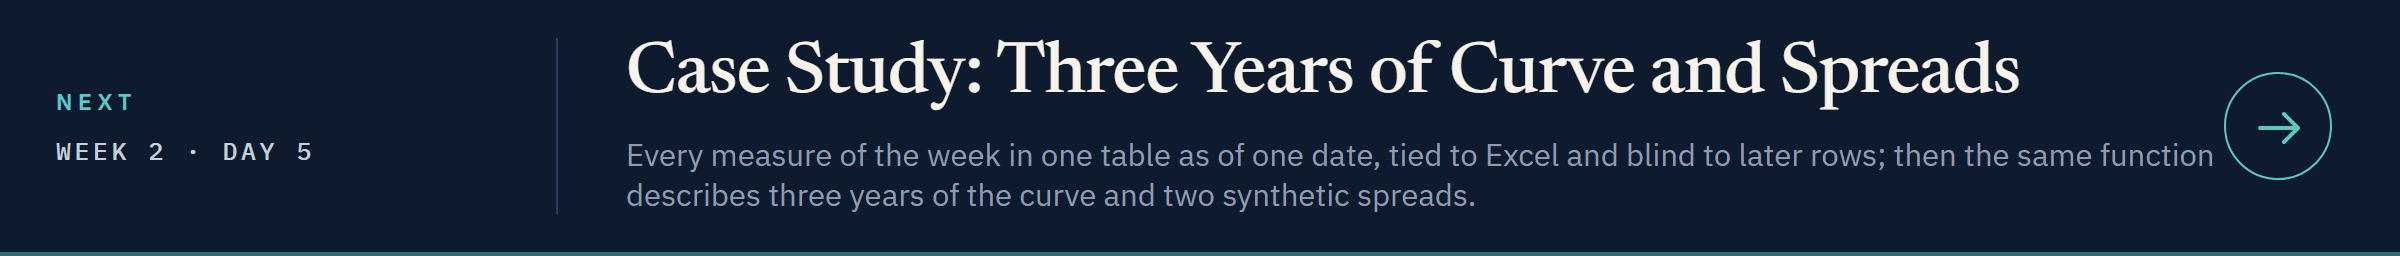](../day5/10_case_study_three_years_of_curve_and_spreads.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day5/10_case_study_three_years_of_curve_and_spreads.ipynb)